# Basic Usage 




## Get a DataFrame from a Table

In [1]:
from arcpy_arrow import tbl_to_df
import os
from pathlib import Path

DB_CONN = Path(os.environ["EGDB_CONN"])                     # A .sde connection file
DB_PREFIX = os.environ["EGDB_PREFIX"]                       # The EGDB prefix

lincoln_tax_data = DB_CONN / f"{DB_PREFIX}LincolnTaxData"

df = tbl_to_df(tbl = lincoln_tax_data,
          field_names=["COUNTYID", "OWNEROCCSTATUS"],
          where_clause = "OWNSTATE <> 'SD'")


df.head()

,COUNTYID,OWNEROCCSTATUS
0,098.49.18.1020,N
1,097.50.18.4030,N
2,097.50.21.3030,N
3,097.50.22.3010,N
4,096.49.35.2010,N


## Get a GeoDataFrame from a Feature Class

In [2]:
from arcpy_arrow import fc_to_gdf

address_points = DB_CONN / f"{DB_PREFIX}Address" / f"{DB_PREFIX}AddressPoints"

gdf = fc_to_gdf(fc = address_points,
               field_names=["ADDRESS", "ALIAS", "LAT", "LON"],
               where_clause="MUNICIPALITY = 'Sioux Falls'"
               )

gdf.head()

,ADDRESS,ALIAS,LAT,LON,geometry
0,2516 W 41ST ST,Crown Casino,43.515087,-96.756511,POINT (2235336.168 15815130.125)
1,3915 S HAWTHORNE AVE,None,43.510267,-96.748968,POINT (2237383.957 15813427.622)
2,2911 W 41ST ST,Super America,43.514270,-96.762194,POINT (2233837.317 15814791.752)
3,1100 W 4TH ST,Terrace Park,43.554453,-96.740961,POINT (2239066.257 15829588.072)
4,3823 S WESTERN AVE,State Farm Bank,43.509747,-96.752259,POINT (2236516.477 15813214.762)


<Axes: >

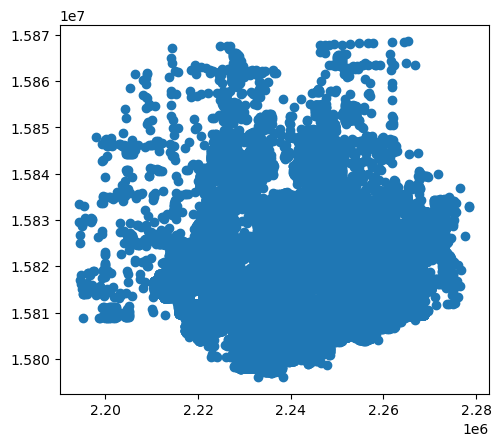

In [3]:
gdf.plot()

## Get a Table from a DataFrame

In [4]:
from arcpy_arrow import df_to_tbl

df_tbl = df_to_tbl(df)

In [5]:
import arcpy 

print(f"Destination: {df_tbl}")
print(f"Row Count: {int(arcpy.management.GetCount(df_tbl).getOutput(0))}")

Destination: memory/fc_3c6e1607f1f341309ee5073e709a9652
Row Count: 1970


In [6]:
tbl_to_df(df_tbl)

,OBJECTID,COUNTYID,OWNEROCCSTATUS
0,1,098.49.18.1020,N
1,2,097.50.18.4030,N
2,3,097.50.21.3030,N
3,4,097.50.22.3010,N
4,5,096.49.35.2010,N
...,...,...,...
1965,1966,096.49.05.1040,N
1966,1967,097.51.34.A100,N
1967,1968,097.51.34.B100,N
1968,1969,098.49.04.2030,N


## Get a Feature Class from a GeoDataFrame

In [7]:
from arcpy_arrow import gdf_to_fc

gdf_fc = gdf_to_fc(gdf = gdf)

In [9]:
arcpy.Describe(gdf_fc)

catalogPath,memory/fc_98d340cbd2fc427f8032d734e4a2fee6
dataType,FeatureClass
shapeType,Point
hasM,False
hasZ,False
OBJECTID,OID
Shape,Geometry
ADDRESS,String
ALIAS,String
LAT,Double
LON,Double
